<div class="alert alert-block alert-info">
<b>✅ NOTA</b>: Este notebook se ha validado con un entorno creado en Anaconda con Python 3.13.15.
</div>

In [1]:
# %run RCR_Bib_Mapas.ipynb

# Boletín 2 - Usando ontologías OWL

Podemos ver una ontología como un vocabulario común sobre un tema, compuesto por una serie de conceptos y relaciones. 
A nivel práctico, esto supone que se tenga este vocabulario fijo, y común para todas las partes que se comuniquen, y que el conocimiento representado esté compuesto por una serie de individuos o instancias de esos conceptos y relaciones.

### Edición y consulta de ontologías con [Protégé](https://protege.stanford.edu/software/#web-protege)

Para poder conocer mejor la ontología podéis utilizar **Protégé**:
   * Abrid esta aplicación.
   * En el panel de abajo elegid `Direct imports`.
   * Elegid la opción `Import an ontology contained in a document located in the web`.
   * En la `URI`poned: http://personales.upv.es/ccarrasc/ocity.owl

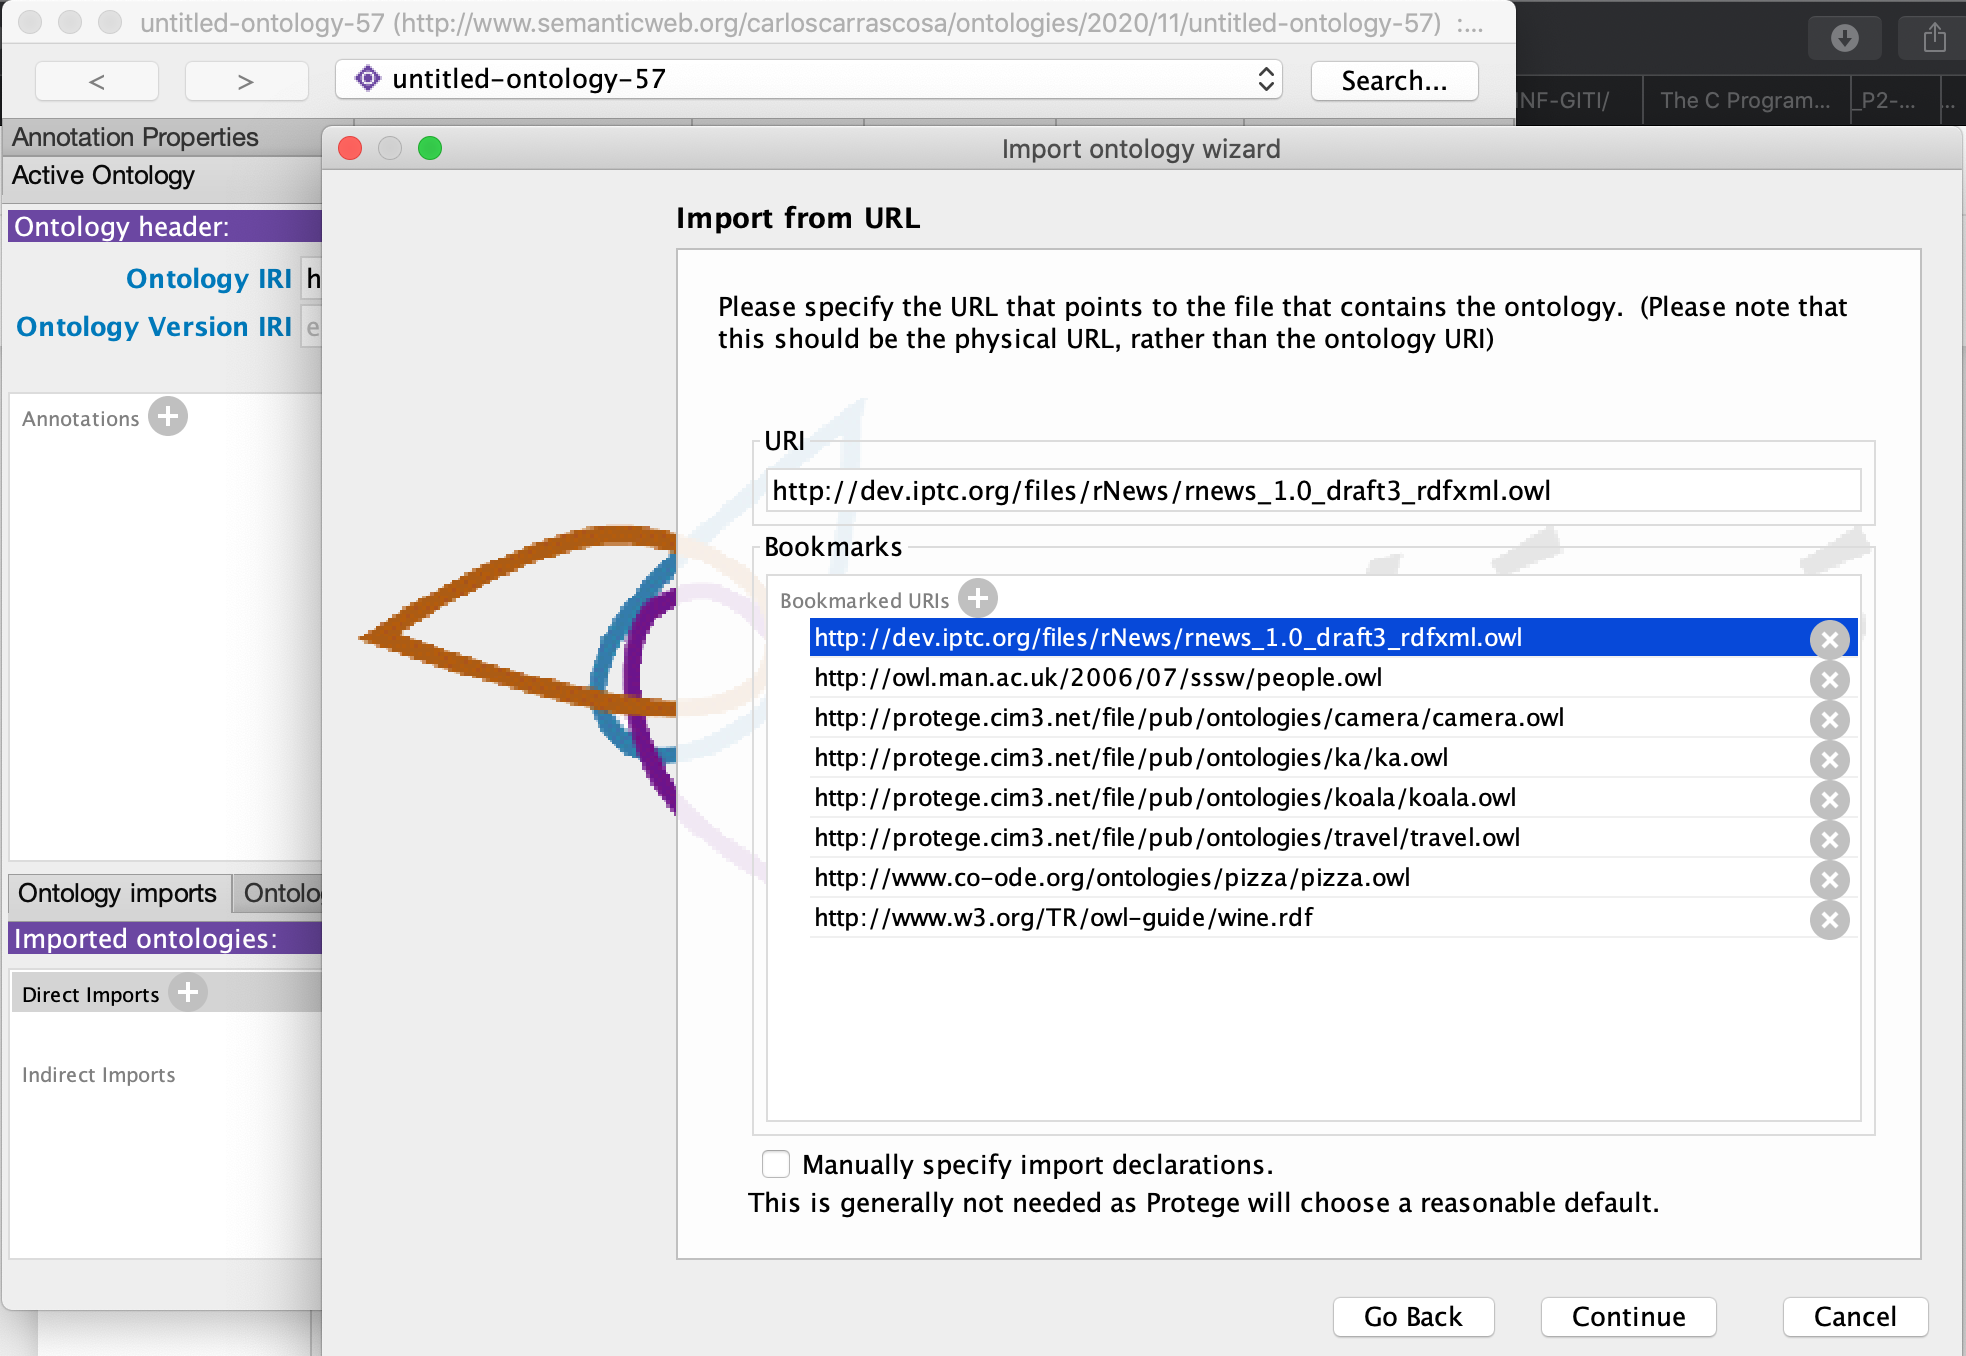

Esto permite importar la ontología y poder consultar cómo está estructurada (clases, propiedades, ...), permitiendo ver cómo podemos estructurar nuestros datos para representarlos usando dicha ontología.

### Visualizacion de Ontologias

Con el fin de poder visualizar las estructuras de nuestras ontologias, podemos usar la web llamada WebOWL.

 WebVOWL es una aplicación web para la visualización interactiva de ontologías. Implementa la Notación Visual para Ontologías OWL (VOWL) proporcionando representaciones gráficas para elementos del Lenguaje de Ontología Web (OWL) que se combinan en un diseño gráfico dirigido por la fuerza que representa la ontología. Las técnicas de interacción permiten explorar la ontología y personalizar la visualización. Las visualizaciones del OWL se generan automáticamente a partir de los archivos JSON en los que las ontologías deben ser convertidas. Se proporciona un convertidor OWL2VOWL basado en Java junto con WebVOWL.

 Podemos ver algunos ejemplos en:
 - [OCity](https://service.tib.eu/webvowl/#iri=http://personales.upv.es/ccarrasc/ocity.owl) - representa la ontología vista https://personales.upv.es/ccarrasc/ocity.owl
 - [FOAF-FriendofaFriend](https://service.tib.eu/webvowl/)

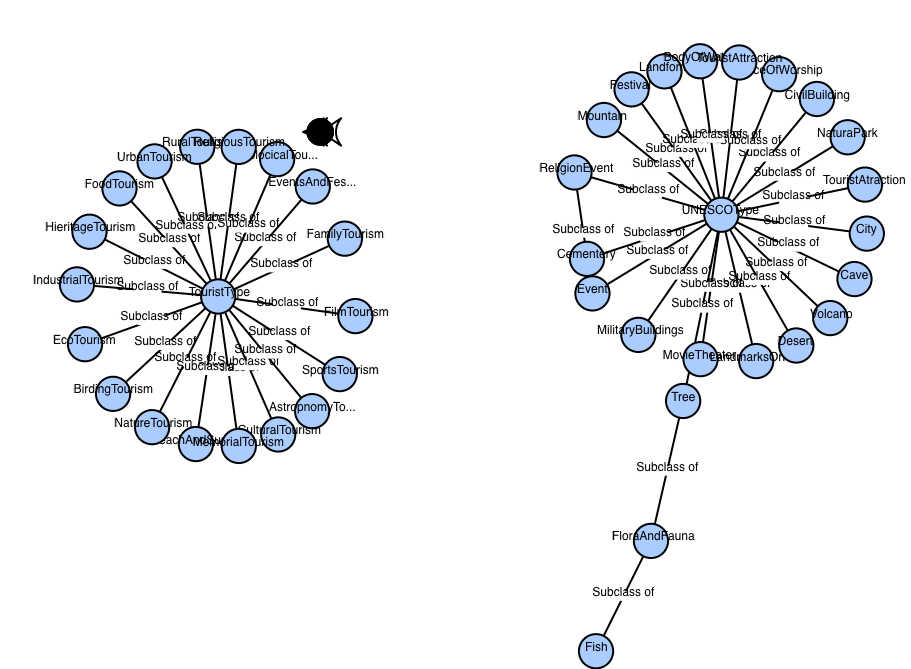

## Gestión de ontología con [OWLReady2](http://pythonhosted.org/Owlready2/index.html)

Owlready2 es una biblioteca de Python que te permite crear, cargar, modificar, consultar y razonar sobre ontologías OWL desde Python. Os dejamos algunos enlaces a la documentación:
- https://pypi.org/project/owlready2/
- https://owlready2.readthedocs.io/en/v0.51/

Esta biblioteca permite importar ontologías, crear entidades, propiedades, atributos, relaciones...

- get_ontology()
- Thing
- ObjectProperty
- DataProperty
- sync_reasoner()

In [2]:
try:
    from owlready2 import *
except:
    !pip install Owlready2==0.51  ### --upgrade
    from owlready2 import *

A continuación, cargamos la ontología a partir de un IRI y, con ella, sus
clases
propiedades
individuos
restricciones... El resultado es un objeto ontology asociado a una url 

In [3]:
onto = get_ontology("http://personales.upv.es/ccarrasc/ocity.owl") 
onto.load() 

get_ontology("http://personales.upv.es/ccarrasc/ocity.owl#")

### Creación de una nueva ontología, que importa la ontología base, para almacenar las instancias (individuos) creados para el ejemplo en cuestión sin modificar la ontología base.



In [4]:
onto_individuals = get_ontology("http://personales.upv.es/ccarrasc/locations_example_individuals.owl")
onto_individuals.imported_ontologies.append(onto) 

In [5]:
onto_individuals.classes()

<generator object _GraphManager.classes at 0x000001C9792F8C70>

### Acceso a la información de la ontología importada

Podemos acceder a diferentes elementos de la ontología: Clases
Propiedades
Individuos
...

dependiendo de los criterios utilizados en la búsqueda.

In [6]:
onto_or = onto_individuals.imported_ontologies.first() # obtenemos la ontología base ocity
on_or  = get_ontology(onto_or.base_iri) # 'http://personales.upv.es/ccarrasc/ocity.owl#'


In [7]:
list(on_or.classes())

[ocity.AdministrativeArchives,
 ocity.AeolianLandforms,
 ocity.Amphibians,
 ocity.AntiquesHeritage,
 ocity.AntropologicalHeritage,
 ocity.AquaticPlantFormations,
 ocity.ArchaeologicalArea,
 ocity.ArchaeologicalSite,
 ocity.ArcheologicalHeritage,
 ocity.ArcheologicalSitesHeritage,
 ocity.ArtHeritage,
 ocity.ArtInstallations,
 ocity.Artefacts,
 ocity.ArtisticAndPerforming,
 ocity.Astronomic,
 ocity.AstropnomyTourism,
 ocity.Atmospheric,
 ocity.Audio-VisualProductions,
 ocity.BeachAndSunTourism,
 ocity.BehaviouralPattern,
 ocity.Belief,
 ocity.Biosphere,
 ocity.BirdingTourism,
 ocity.Birds,
 ocity.BodyOfWater,
 ocity.Books,
 ocity.BuildingAndMonumentHeritage,
 ocity.Cave,
 ocity.Celebration,
 ocity.Cementery,
 ocity.ChildrensGame,
 ocity.City,
 ocity.CivilBuilding,
 ocity.ClosedForests,
 ocity.CommemorativeWorks,
 ocity.CookingMethod,
 ocity.Craftwork,
 ocity.CulturalTourism,
 ocity.CurturalHeritage,
 ocity.CustomaryLegalSystem,
 ocity.Dance,
 ocity.DecoratedBones,
 ocity.DecorativeArts,


In [8]:
list(on_or.properties())

[ocity.about,
 ocity.addressCountry,
 ocity.addressLocality,
 ocity.description,
 ocity.extras,
 ocity.id,
 ocity.image,
 ocity.latitude,
 ocity.longitude,
 ocity.name,
 ocity.url,
 ocity.hasPreferenceFor,
 ocity.hasUNEType,
 ocity.isAppropriateFor]

In [9]:
list(on_or.object_properties())

[ocity.hasPreferenceFor, ocity.hasUNEType, ocity.isAppropriateFor]

In [10]:
list(on_or.data_properties())

[ocity.about,
 ocity.addressCountry,
 ocity.addressLocality,
 ocity.description,
 ocity.extras,
 ocity.id,
 ocity.image,
 ocity.latitude,
 ocity.longitude,
 ocity.name,
 ocity.url]

Buscar una entidad de la ontología por su IRI y después crear un individuo a partir de una de las entidades encontradas.

In [11]:
# Busca en on_or entidades cuya IRI - identificador - contenga Landmarks.
v = on_or.search(iri = "*Landmarks*")
v

[ocity.LandmarksOrHistoricalBuildings]

In [12]:
r = on_or.search(iri = "*Buildings*") 
print(r)  

[ocity.LandmarksOrHistoricalBuildings, ocity.MilitaryBuildings]


Podemos crear instancias también en la ontología: en este caso creamos una instancia/objeto de esa clase especificada (ocity.MilitaryBuildings)


In [13]:
onto_individuals.individual = r[0]()
onto_individuals.individual

ocity.landmarksorhistoricalbuildings1

Ahora completamos la información del objeto del tipo BuildingMilitar que acabamos de crear acorde a las propiedades (data_properties) de las entidades de la ontología. 

In [14]:
onto_individuals.individual.name = 'Estadio Mestalla'
onto_individuals.individual.addressCountry.append('Spain') # name es una DataProperty de la ontología
onto_individuals.individual.addressLocality.append('Valencia') # Esto es posible porque en OWL una propiedad puede tener varios valores, lo añadimos como lista

In [15]:
print(onto_individuals.individual)
print(onto_individuals.individual.addressCountry)
print(onto_individuals.individual.addressLocality)

ocity.Estadio Mestalla
['Spain']
['Valencia']


### Localizando en un mapa una instancia de OWLReady2

In [ ]:
import openrouteservice
import folium

def add_marker(m, coords, text="", color="red", icon="info-sign"):
    folium.map.Marker(list(reversed(coords)),
                      icon=folium.Icon(color=color,
                                       icon=icon
                                       ),
                      popup=text,
                      ).add_to(m)
    return m

def add_marker_fa(m, coords, text="", color="red", icon="info-sign"):
    folium.map.Marker(list(reversed(coords)),
                      icon=folium.Icon(color=color,
                                       icon=icon,
                                       prefix='fa'
                                       ),
                      popup=text,
                      ).add_to(m)
    return m
    
def create_map(center, zoom=14):
    m = folium.Map(location=list(reversed(center)), zoom_start=zoom)
    return m

def geocoding(client, place, focus):
    try:
        #r = openrouteservice.geocode.pelias_structured(client,
        #                    address=place['calle'], locality=place['ciudad'],
        #                    postalcode=place['cp'], country=place['pais'])
        r = openrouteservice.geocode.pelias_search(client, text=place, 
                                                   focus_point=focus)
        coords = r['features'][0]['geometry']['coordinates']
        return coords
    except:
        return None

def add_ruta_ant(m, ruta, color="red"):
    rev_ruta = []
    for x in ruta:
        rev_ruta.append(list(reversed(x)))
        
    folium.plugins.AntPath(rev_ruta, color=color).add_to(m)
    return m   

def crea_ruta (mapa, client, coordenadas, color='red', tipo='foot-walking'):
    # tipo es un valor entre 
    ### [“driving-car”, “driving-hgv”, “foot-walking”, “foot-hiking”, “cycling-regular”, 
    ### “cycling-road”,”cycling-mountain”, “cycling-electric”]

    route = client.directions(coordinates=coordenadas,
                                  profile=tipo,
                                  format='geojson')
    
    ruta = route['features'][0]['geometry']['coordinates']
    mapa = add_ruta_ant(mapa, ruta, color=color)
    
    suma = 0
    segments = route['features'][0]['properties']['segments']
    for i in segments:
        print(i['distance'])
        suma = suma + i['distance']

    return {'distancia': suma, 'mapa': mapa, 'ruta': ruta}
    
client = openrouteservice.Client(key='') #introduce aquí la API utilizada en la PL1 de openrouteservice
    
place = onto_individuals.individual.name + ', ' + onto_individuals.individual.addressLocality[0] + ', ' + onto_individuals.individual.addressCountry[0]
focus = [39.459,-0.385]

coords = geocoding(client, place, focus)

if coords is not None:
    m = create_map(coords)
    m = add_marker(m, coords, text=place) 
m

### Eliminar todas las instancias de la ontología de pruebas anteriores.

In [17]:
indiv_list = on_or.search(iri = "*Military*")
print(indiv_list)
for indiv in indiv_list:
    destroy_entity(indiv)

[ocity.MilitaryBuildings, ocity.MilitaryObjects]


In [18]:
indiv_list = onto_individuals.search(iri = "*Military*")
for indiv in indiv_list:
    destroy_entity(indiv)

| Ejercicio 1 |
|------------:|
| Volver a cargar la estructura **Pandas** con la que trabajando en el boletín anterior a partir del fichero **CSV** denominado `datos_valencia.csv` en el que la guardaste. |

| Ejercicio 2 |
|------------:|
| Realiza una función que reciba como parámetros una estructura **Pandas** como la resultado del ejercicio anterior y una ontología que herede de **ocity** como la que hemos usado, y añada las instancias oportunas en la ontología que permitan guardar la información de la estructura **Pandas**. La función debe acabar devolviendo la ontología modificada. |

| Ejercicio 3 |
|------------:|
| Usa la función resultado del ejercicio anterior para añadir a la ontología que tienes las instancias oportunas fruto de la estructura **Pandas** que construimos en el boletín anterior. |

## Inspiración para nuestro objetivo en Valencia

Haciendo un guiño a la recomendación habitual de la OMS de dar 10 000 pasos al día, esta propuesta Visit Norway invita a participar en su proyecto «10 000 pasos». Asignando una rutade entre 7 y 8 kilómetros y asegurándose de que pasaran por todos los lugares más destacados de su aventura noruega. Para más información - [Ciudades Noruegas en 10000 pasos](https://www.visitnorway.com/places-to-go/city-break/10000-steps/)

### Clase Ruta

| Ejercicio 3 |
|------------:|
| Crea la clase **Ruta** en la ontología que estamos trabajando. Dicha clase debe contener una `object property` que incluya las instancias de todos los edificios, monumentos, ... que se quieren visitar en dicha ruta, así como una `object property` con los posibles tipos de turismo para los que puede tener interés dicha ruta y dos `data property`: una que indique la distancia en metros necesaria para recorrer dicha ruta, y un nombre para identificar dicha ruta. |

| Ejercicio 4 |
|------------:|
| Crea al menos 5 instancias de la clase **Ruta** que deben incluir las 5 rutas que comiencen cada una por el edificio o monumento que tenemos almacenado que se encuentre más al oeste (es decir, una ruta por cada uno de los 5 monumentos más al oeste). Además estas rutas deben tener un recorrido lo más cercano posible a los 10000 pasos (alrededor de 7 km). |

| Ejercicio 5 |
|------------:|
| Crea una función que reciba un mapa y una instancia de la clase **Ruta** de la ontología que estamos trabajando y devuelva un mapa con los marcadores oportunos para cada punto de la ruta y un `AntPath` uniéndolos. |

| Ejercicio 6 |
|------------:|
| Crea una nueva ruta asociada a turismo deportivo que incluya al menos 3 edificios o monumentos que puedan asociarse a tal fin y guarda para ello todos los datos que necesites en la ontología que estamos trabajando. Además, crea un mapa donde se muestre dicha ruta. |

| Ejercicio 7 |
|------------:|
| Crea un mapa y utilizando la función del ejercicio 5 pinta en él todas las rutas almacenadas actualmente en la ontología que estamos trabajando. |

| Ejercicio 8 |
|------------:|
| Guarda la ontología que hemos creado en un fichero llamado `pract2.owl` y comprueba que tiene los individuos y la clase que hemos añadido. |